In [1]:
# ==========================================
# 1. General Utilities
# ==========================================
import os
import warnings
from pathlib import Path
from datetime import datetime, timedelta
warnings.filterwarnings("ignore")
# ==========================================
# 2. Data Manipulation
# ==========================================
import pandas as pd
import numpy as np
# ==========================================
# 3. Data Visualization
# ==========================================
import matplotlib.pyplot as plt
import seaborn as sns
# ==========================================
# 4. Database Connection
# ==========================================
from dotenv import load_dotenv
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL
# ==========================================
# 5. Data Preprocessing
# ==========================================
from sklearn.model_selection import (
    train_test_split,
    cross_val_score,
    GridSearchCV,
    RandomizedSearchCV
)
from sklearn.preprocessing import (
    StandardScaler,
    MinMaxScaler,
    OneHotEncoder,
    LabelEncoder
)
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
# ==========================================
# 6. Machine Learning - Regression
# ==========================================
from sklearn.linear_model import (
    LinearRegression,
    Ridge,
    Lasso
)
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor,
    AdaBoostRegressor,
    IsolationForest
)
# ==========================================
# 7. Machine Learning - Classification
# ==========================================
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier,
    AdaBoostClassifier
)
# ==========================================
# 8. Model Evaluation
# ==========================================
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error,
    r2_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score)
# ==========================================
# 9. Anomaly Detection and Clustering
# ==========================================
from sklearn.cluster import DBSCAN, KMeans
from sklearn.decomposition import PCA
from sklearn.neighbors import LocalOutlierFactor
# ==========================================
# 10. Model Saving and Loading
# ==========================================
import joblib
# ==========================================
# 11. FastAPI - Later, for API integration
# ==========================================
from fastapi import FastAPI, HTTPException
from pydantic import BaseModel
print("All SmartSpend AI libraries imported successfully!")

All SmartSpend AI libraries imported successfully!


In [2]:
import os
from pathlib import Path
from dotenv import load_dotenv
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL
# Find the project root containing .env
current = Path.cwd().resolve()
project_root = next(
    (p for p in [current, *current.parents] if (p / ".env").is_file()),
    None)
if project_root is None:
    raise FileNotFoundError(
        "Could not find .env. Open Jupyter from your project "
        "or update the .env path below.")
load_dotenv(project_root / ".env", override=False)
# Read database settings
database_url = os.getenv("DATABASE_URL")
if database_url:
    engine = create_engine(database_url, pool_pre_ping=True)
else:
    # Adjust these names if your .env uses different variable names.
    db_name = os.getenv("DB_NAME") or os.getenv("DB_DATABASE")
    db_user = os.getenv("DB_USER") or os.getenv("DB_USERNAME")
    db_password = os.getenv("DB_PASSWORD") or os.getenv("DB_PASS")
    db_host = os.getenv("DB_HOST", "localhost")
    db_port = os.getenv("DB_PORT", "5432")
    if not all([db_name, db_user, db_password]):
        raise ValueError(
            "Database settings missing. Check the variable names "
            "in your project's .env file.")
    db_url = URL.create(
        drivername="postgresql+psycopg2",
        username=db_user,
        password=db_password,
        host=db_host,
        port=int(db_port),
        database=db_name)
    engine = create_engine(db_url, pool_pre_ping=True)
# Test connection
with engine.connect() as connection:
    result = connection.execute(text("SELECT current_database(), version()"))
    database, version = result.fetchone()
print("PostgreSQL connected successfully!")
print("Database:", database)
print("Connection is ready for SmartSpend AI.")

PostgreSQL connected successfully!
Database: smart spend ai
Connection is ready for SmartSpend AI.


In [3]:
budgets_query = text("""
    SELECT *
    FROM budgets
""")
categories_query = text("""
    SELECT *
    FROM categories
""")
users_query = text("""
    SELECT *
    FROM users
""")
with engine.connect() as connection:
    budgets_df = pd.read_sql(budgets_query, connection)
    categories_df = pd.read_sql(categories_query, connection)
    users_df = pd.read_sql(users_query, connection)
print("Budget records:", len(budgets_df))
print("Category records:", len(categories_df))
print("\nBudget columns:")
print(budgets_df.columns.tolist())
print("\nCategory columns:")
print(categories_df.columns.tolist())
display(budgets_df.head())
display(categories_df.head())

Budget records: 8
Category records: 14

Budget columns:
['id', 'user_id', 'category_id', 'amount_limit', 'period', 'start_date', 'end_date', 'created_at', 'updated_at']

Category columns:
['id', 'user_id', 'name', 'type', 'icon', 'is_system', 'created_at', 'updated_at']


,id,user_id,category_id,amount_limit,period,start_date,end_date,created_at,updated_at
0,1,4,6,3000.0,monthly,2026-06-01,2026-06-30,2026-10-26 04:58:16.996000+00:00,2026-10-26 04:58:16.996000+00:00
1,2,4,7,2000.0,monthly,2026-06-01,2026-06-30,2026-10-26 04:58:17.006000+00:00,2026-10-26 04:58:17.006000+00:00
2,3,4,8,1200.0,monthly,2026-06-01,2026-06-30,2026-10-26 04:58:17.011000+00:00,2026-10-26 04:58:17.011000+00:00
3,4,4,10,1500.0,monthly,2026-06-01,2026-06-30,2026-10-26 04:58:17.018000+00:00,2026-10-26 04:58:17.018000+00:00
4,5,5,6,3500.0,monthly,2026-06-01,2026-06-30,2026-10-26 04:58:17.026000+00:00,2026-10-26 04:58:17.026000+00:00


,id,user_id,name,type,icon,is_system,created_at,updated_at
0,1,1.0,Demo Food,expense,utensils,False,2026-10-12 04:40:14.282000+00:00,2026-10-12 04:40:14.282000+00:00
1,2,2.0,Demo Food,expense,utensils,False,2026-10-12 05:48:48.925000+00:00,2026-10-12 05:48:48.925000+00:00
2,3,3.0,Demo Food,expense,utensils,False,2026-10-12 15:24:26.431000+00:00,2026-10-12 15:24:26.431000+00:00
3,4,NaN,Salary,income,wallet,True,2026-10-26 04:58:15.582000+00:00,2026-10-26 04:58:15.582000+00:00
4,5,NaN,Freelance,income,laptop,True,2026-10-26 04:58:15.589000+00:00,2026-10-26 04:58:15.589000+00:00


In [4]:
print("NULL values in budgets_df:")
display(budgets_df.isnull().sum())
print("\nNULL values in categories_df:")
display(categories_df.isnull().sum())

NULL values in budgets_df:


id              0
user_id         0
category_id     0
amount_limit    0
period          0
start_date      0
end_date        0
created_at      0
updated_at      0
dtype: int64


NULL values in categories_df:


id             0
user_id       11
name           0
type           0
icon           0
is_system      0
created_at     0
updated_at     0
dtype: int64

In [5]:
print("Categories with NULL user_id:")
display(
    categories_df.loc[
        categories_df["user_id"].isna()])

Categories with NULL user_id:


,id,user_id,name,type,icon,is_system,created_at,updated_at
3,4,NaN,Salary,income,wallet,True,2026-10-26 04:58:15.582000+00:00,2026-10-26 04:58:15.582000+00:00
4,5,NaN,Freelance,income,laptop,True,2026-10-26 04:58:15.589000+00:00,2026-10-26 04:58:15.589000+00:00
5,6,NaN,Groceries,expense,shopping-basket,True,2026-10-26 04:58:15.594000+00:00,2026-10-26 04:58:15.594000+00:00
6,7,NaN,Food & Dining,expense,utensils,True,2026-10-26 04:58:15.599000+00:00,2026-10-26 04:58:15.599000+00:00
7,8,NaN,Transport,expense,bus,True,2026-10-26 04:58:15.605000+00:00,2026-10-26 04:58:15.605000+00:00
8,9,NaN,Bills & Utilities,expense,receipt,True,2026-10-26 04:58:15.611000+00:00,2026-10-26 04:58:15.611000+00:00
9,10,NaN,Shopping,expense,shopping-bag,True,2026-10-26 04:58:15.615000+00:00,2026-10-26 04:58:15.615000+00:00
10,11,NaN,Entertainment,expense,film,True,2026-10-26 04:58:15.620000+00:00,2026-10-26 04:58:15.620000+00:00
11,12,NaN,Health,expense,heart-pulse,True,2026-10-26 04:58:15.626000+00:00,2026-10-26 04:58:15.626000+00:00
12,13,NaN,Education,expense,book-open,True,2026-10-26 04:58:15.629000+00:00,2026-10-26 04:58:15.629000+00:00


In [6]:
# Inspect category ownership and category type
display(
    categories_df[
        ["id", "name", "user_id"]
    ].sort_values("name"))
print("Total categories:", len(categories_df))
print("System categories (NULL user_id):",
      categories_df["user_id"].isna().sum())
print("User-specific categories:",
      categories_df["user_id"].notna().sum())
print("Duplicate category IDs:",
      categories_df["id"].duplicated().sum())

,id,name,user_id
8,9,Bills & Utilities,NaN
0,1,Demo Food,1.0
1,2,Demo Food,2.0
2,3,Demo Food,3.0
12,13,Education,NaN
10,11,Entertainment,NaN
6,7,Food & Dining,NaN
4,5,Freelance,NaN
5,6,Groceries,NaN
11,12,Health,NaN


Total categories: 14
System categories (NULL user_id): 11
User-specific categories: 3
Duplicate category IDs: 0


In [7]:
# Check whether budgets reference valid users and categories
print("Budget columns:", budgets_df.columns.tolist())
print("User columns:", users_df.columns.tolist())
print("Category columns:", categories_df.columns.tolist())

Budget columns: ['id', 'user_id', 'category_id', 'amount_limit', 'period', 'start_date', 'end_date', 'created_at', 'updated_at']
User columns: ['id', 'first_name', 'last_name', 'email', 'password_hash', 'currency', 'created_at', 'updated_at']
Category columns: ['id', 'user_id', 'name', 'type', 'icon', 'is_system', 'created_at', 'updated_at']


In [8]:
# Check for missing and invalid foreign-key references
valid_user_ids = set(users_df["id"].dropna())
valid_category_ids = set(categories_df["id"].dropna())
invalid_user_mask = (
    budgets_df["user_id"].isna()
    | ~budgets_df["user_id"].isin(valid_user_ids))
invalid_category_mask = (
    budgets_df["category_id"].isna()
    | ~budgets_df["category_id"].isin(valid_category_ids))
print("Budgets with missing/invalid user IDs:",
      int(invalid_user_mask.sum()))
print("Budgets with missing/invalid category IDs:",
      int(invalid_category_mask.sum()))
print("\nInvalid user references:")
display(budgets_df.loc[invalid_user_mask])
print("\nInvalid category references:")
display(budgets_df.loc[invalid_category_mask])

Budgets with missing/invalid user IDs: 0
Budgets with missing/invalid category IDs: 0

Invalid user references:


,id,user_id,category_id,amount_limit,period,start_date,end_date,created_at,updated_at



Invalid category references:


,id,user_id,category_id,amount_limit,period,start_date,end_date,created_at,updated_at


In [9]:
budgets_df["amount_limit"] = pd.to_numeric(
    budgets_df["amount_limit"], errors="coerce")
print("Missing/non-numeric budget amounts:",
      int(budgets_df["amount_limit"].isna().sum()))
print("Zero budget amounts:",
      int((budgets_df["amount_limit"] == 0).sum()))
print("Negative budget amounts:",
      int((budgets_df["amount_limit"] < 0).sum()))
display(
    budgets_df.loc[
        budgets_df["amount_limit"].isna()
        | (budgets_df["amount_limit"] <= 0)])

Missing/non-numeric budget amounts: 0
Zero budget amounts: 0
Negative budget amounts: 0


,id,user_id,category_id,amount_limit,period,start_date,end_date,created_at,updated_at


In [10]:
print("Budget columns:", budgets_df.columns.tolist())
display(budgets_df.head(10))

Budget columns: ['id', 'user_id', 'category_id', 'amount_limit', 'period', 'start_date', 'end_date', 'created_at', 'updated_at']


,id,user_id,category_id,amount_limit,period,start_date,end_date,created_at,updated_at
0,1,4,6,3000.0,monthly,2026-06-01,2026-06-30,2026-10-26 04:58:16.996000+00:00,2026-10-26 04:58:16.996000+00:00
1,2,4,7,2000.0,monthly,2026-06-01,2026-06-30,2026-10-26 04:58:17.006000+00:00,2026-10-26 04:58:17.006000+00:00
2,3,4,8,1200.0,monthly,2026-06-01,2026-06-30,2026-10-26 04:58:17.011000+00:00,2026-10-26 04:58:17.011000+00:00
3,4,4,10,1500.0,monthly,2026-06-01,2026-06-30,2026-10-26 04:58:17.018000+00:00,2026-10-26 04:58:17.018000+00:00
4,5,5,6,3500.0,monthly,2026-06-01,2026-06-30,2026-10-26 04:58:17.026000+00:00,2026-10-26 04:58:17.026000+00:00
5,6,5,7,2200.0,monthly,2026-06-01,2026-06-30,2026-10-26 04:58:17.032000+00:00,2026-10-26 04:58:17.032000+00:00
6,7,6,6,2500.0,monthly,2026-06-01,2026-06-30,2026-10-26 04:58:17.039000+00:00,2026-10-26 04:58:17.039000+00:00
7,8,7,6,3000.0,monthly,2026-06-01,2026-06-30,2026-10-26 04:58:17.045000+00:00,2026-10-26 04:58:17.045000+00:00


In [11]:
transactions_query = text("""
    SELECT
        id,
        user_id,
        category_id,
        amount,
        transaction_type,
        transaction_date
    FROM transactions
    WHERE transaction_type = 'expense';
""")
with engine.connect() as connection:
    budget_transactions_df = pd.read_sql(
        transactions_query, connection)
budget_transactions_df["transaction_date"] = pd.to_datetime(
    budget_transactions_df["transaction_date"],
    utc=True)
print("Expense transactions loaded:", len(budget_transactions_df))
display(budget_transactions_df.head())

Expense transactions loaded: 221


,id,user_id,category_id,amount,transaction_type,transaction_date
0,1,1,1,250.0,expense,2026-10-12 00:00:00+00:00
1,3,2,2,120.0,expense,2026-10-12 00:00:00+00:00
2,2,2,2,250.0,expense,2026-10-12 00:00:00+00:00
3,6,3,3,120.0,expense,2026-10-12 00:00:00+00:00
4,5,3,3,250.0,expense,2026-10-12 00:00:00+00:00


In [12]:
# Convert budget dates to datetime
budgets_df["start_date"] = pd.to_datetime(
    budgets_df["start_date"], utc=True)
budgets_df["end_date"] = pd.to_datetime(
    budgets_df["end_date"], utc=True)
# Calculate actual spending for each budget
budget_analysis_df = budgets_df.copy()
actual_spending = []
for _, budget in budget_analysis_df.iterrows():
    matching_transactions = budget_transactions_df[
        (budget_transactions_df["user_id"] == budget["user_id"])
        & (budget_transactions_df["category_id"] == budget["category_id"])
        & (budget_transactions_df["transaction_date"] >= budget["start_date"])
        & (budget_transactions_df["transaction_date"] < (
            budget["end_date"] + pd.Timedelta(days=1)))]
    actual_spending.append(
        matching_transactions["amount"].sum())
budget_analysis_df["actual_spending"] = actual_spending
# Calculate remaining budget and utilization
budget_analysis_df["remaining_budget"] = (
    budget_analysis_df["amount_limit"]
    - budget_analysis_df["actual_spending"])
budget_analysis_df["utilization_pct"] = (
    budget_analysis_df["actual_spending"]
    / budget_analysis_df["amount_limit"]
    * 100)
display(
    budget_analysis_df[
        [
            "user_id",
            "category_id",
            "period",
            "amount_limit",
            "actual_spending",
            "remaining_budget",
            "utilization_pct"
        ]
    ].round(2))

,user_id,category_id,period,amount_limit,actual_spending,remaining_budget,utilization_pct
0,4,6,monthly,3000.0,6200.0,-3200.0,206.67
1,4,7,monthly,2000.0,1600.0,400.0,80.00
2,4,8,monthly,1200.0,900.0,300.0,75.00
3,4,10,monthly,1500.0,1200.0,300.0,80.00
4,5,6,monthly,3500.0,3100.0,400.0,88.57
5,5,7,monthly,2200.0,1800.0,400.0,81.82
6,6,6,monthly,2500.0,1950.0,550.0,78.00
7,7,6,monthly,3000.0,2600.0,400.0,86.67


In [13]:
def classify_budget(utilization):
    if utilization > 100:
        return "Exceeded"
    elif utilization >= 80:
        return "Near Limit"
    else:
        return "Within Budget"
budget_analysis_df["budget_status"] = (
    budget_analysis_df["utilization_pct"]
    .apply(classify_budget))
display(
    budget_analysis_df[
        [
            "user_id",
            "category_id",
            "amount_limit",
            "actual_spending",
            "remaining_budget",
            "utilization_pct",
            "budget_status"]].round(2))

,user_id,category_id,amount_limit,actual_spending,remaining_budget,utilization_pct,budget_status
0,4,6,3000.0,6200.0,-3200.0,206.67,Exceeded
1,4,7,2000.0,1600.0,400.0,80.00,Near Limit
2,4,8,1200.0,900.0,300.0,75.00,Within Budget
3,4,10,1500.0,1200.0,300.0,80.00,Near Limit
4,5,6,3500.0,3100.0,400.0,88.57,Near Limit
5,5,7,2200.0,1800.0,400.0,81.82,Near Limit
6,6,6,2500.0,1950.0,550.0,78.00,Within Budget
7,7,6,3000.0,2600.0,400.0,86.67,Near Limit


In [14]:
def generate_budget_insight(row):
    category_name = categories_df.loc[
        categories_df["id"] == row["category_id"],
        "name"]
    category_name = (
        category_name.iloc[0]
        if not category_name.empty
        else f"Category {row['category_id']}")
    if row["budget_status"] == "Exceeded":
        excess = abs(row["remaining_budget"])
        return (
            f"Your {category_name} spending is ₹"
            f"{row['actual_spending']:.2f} against a budget of "
            f"₹{row['amount_limit']:.2f}. You exceeded your "
            f"budget by ₹{excess:.2f}.")
    elif row["budget_status"] == "Near Limit":
        return (
            f"You have used {row['utilization_pct']:.1f}% of your "
            f"{category_name} budget. ₹"
            f"{row['remaining_budget']:.2f} remains.")
    else:
        return (
            f"Your {category_name} spending is within budget. "
            f"₹{row['remaining_budget']:.2f} remains.")
budget_analysis_df["financial_insight"] = (
    budget_analysis_df.apply(generate_budget_insight, axis=1))
with pd.option_context("display.max_colwidth", None):
    display(
        budget_analysis_df[
            ["user_id", "category_id", "budget_status", "financial_insight"]])

,user_id,category_id,budget_status,financial_insight
0,4,6,Exceeded,Your Groceries spending is ₹6200.00 against a budget of ₹3000.00. You exceeded your budget by ₹3200.00.
1,4,7,Near Limit,You have used 80.0% of your Food & Dining budget. ₹400.00 remains.
2,4,8,Within Budget,Your Transport spending is within budget. ₹300.00 remains.
3,4,10,Near Limit,You have used 80.0% of your Shopping budget. ₹300.00 remains.
4,5,6,Near Limit,You have used 88.6% of your Groceries budget. ₹400.00 remains.
5,5,7,Near Limit,You have used 81.8% of your Food & Dining budget. ₹400.00 remains.
6,6,6,Within Budget,Your Groceries spending is within budget. ₹550.00 remains.
7,7,6,Near Limit,You have used 86.7% of your Groceries budget. ₹400.00 remains.


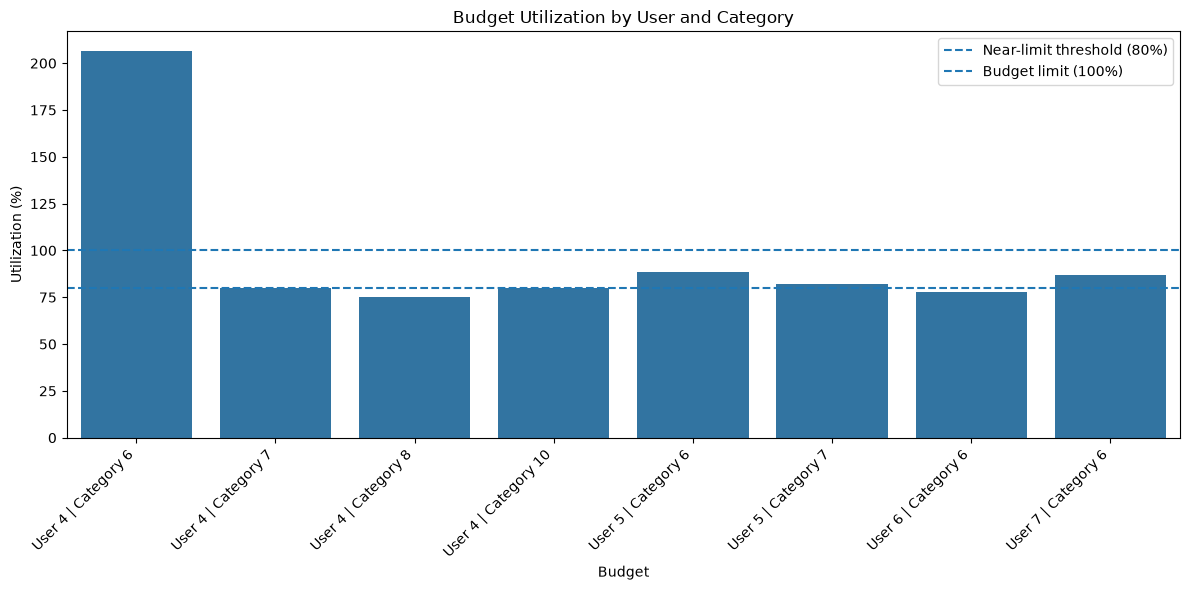

In [15]:
plt.figure(figsize=(12, 6))
plot_df = budget_analysis_df.copy()
plot_df["budget_label"] = (
    "User " + plot_df["user_id"].astype(str)
    + " | Category " + plot_df["category_id"].astype(str))
sns.barplot(
    data=plot_df,
    x="budget_label",
    y="utilization_pct")
plt.axhline(
    80,
    linestyle="--",
    label="Near-limit threshold (80%)")
plt.axhline(
    100,
    linestyle="--",
    label="Budget limit (100%)")
plt.title("Budget Utilization by User and Category")
plt.xlabel("Budget")
plt.ylabel("Utilization (%)")
plt.xticks(rotation=45, ha="right")
plt.legend()
plt.tight_layout()
plt.show()